In [398]:
import kagglehub

# Download latest version
path = kagglehub.competition_download("playground-series-s4e1")

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/playground-series-s4e1


In [399]:
import math
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb

pd.set_option('display.max_columns', None)

In [400]:
# Load data
train = pd.read_csv(Path(path) / "train.csv")
test = pd.read_csv(Path(path) / "test.csv")

print(train.shape, test.shape)

(165034, 14) (110023, 13)


In [401]:
train.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [402]:
train.isnull().sum()

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [403]:
test.isnull().sum()

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
dtype: int64

In [404]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  object 
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  object 
 5   Gender           165034 non-null  object 
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 17.6+ MB


In [405]:
train['Gender'].value_counts()

Gender
Male      93150
Female    71884
Name: count, dtype: int64

In [406]:
train['Geography'].value_counts()

Geography
France     94215
Spain      36213
Germany    34606
Name: count, dtype: int64

In [407]:
train['Exited'].value_counts(normalize=True)

Exited
0    0.788401
1    0.211599
Name: proportion, dtype: float64

In [408]:
numeric_cols = train.select_dtypes(include="number").columns
numeric_cols = numeric_cols.drop(['id', 'CustomerId']).tolist()
numeric_cols

['CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

array([[<Axes: title={'center': 'CreditScore'}>,
        <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Tenure'}>],
       [<Axes: title={'center': 'Balance'}>,
        <Axes: title={'center': 'NumOfProducts'}>,
        <Axes: title={'center': 'HasCrCard'}>],
       [<Axes: title={'center': 'IsActiveMember'}>,
        <Axes: title={'center': 'EstimatedSalary'}>,
        <Axes: title={'center': 'Exited'}>]], dtype=object)

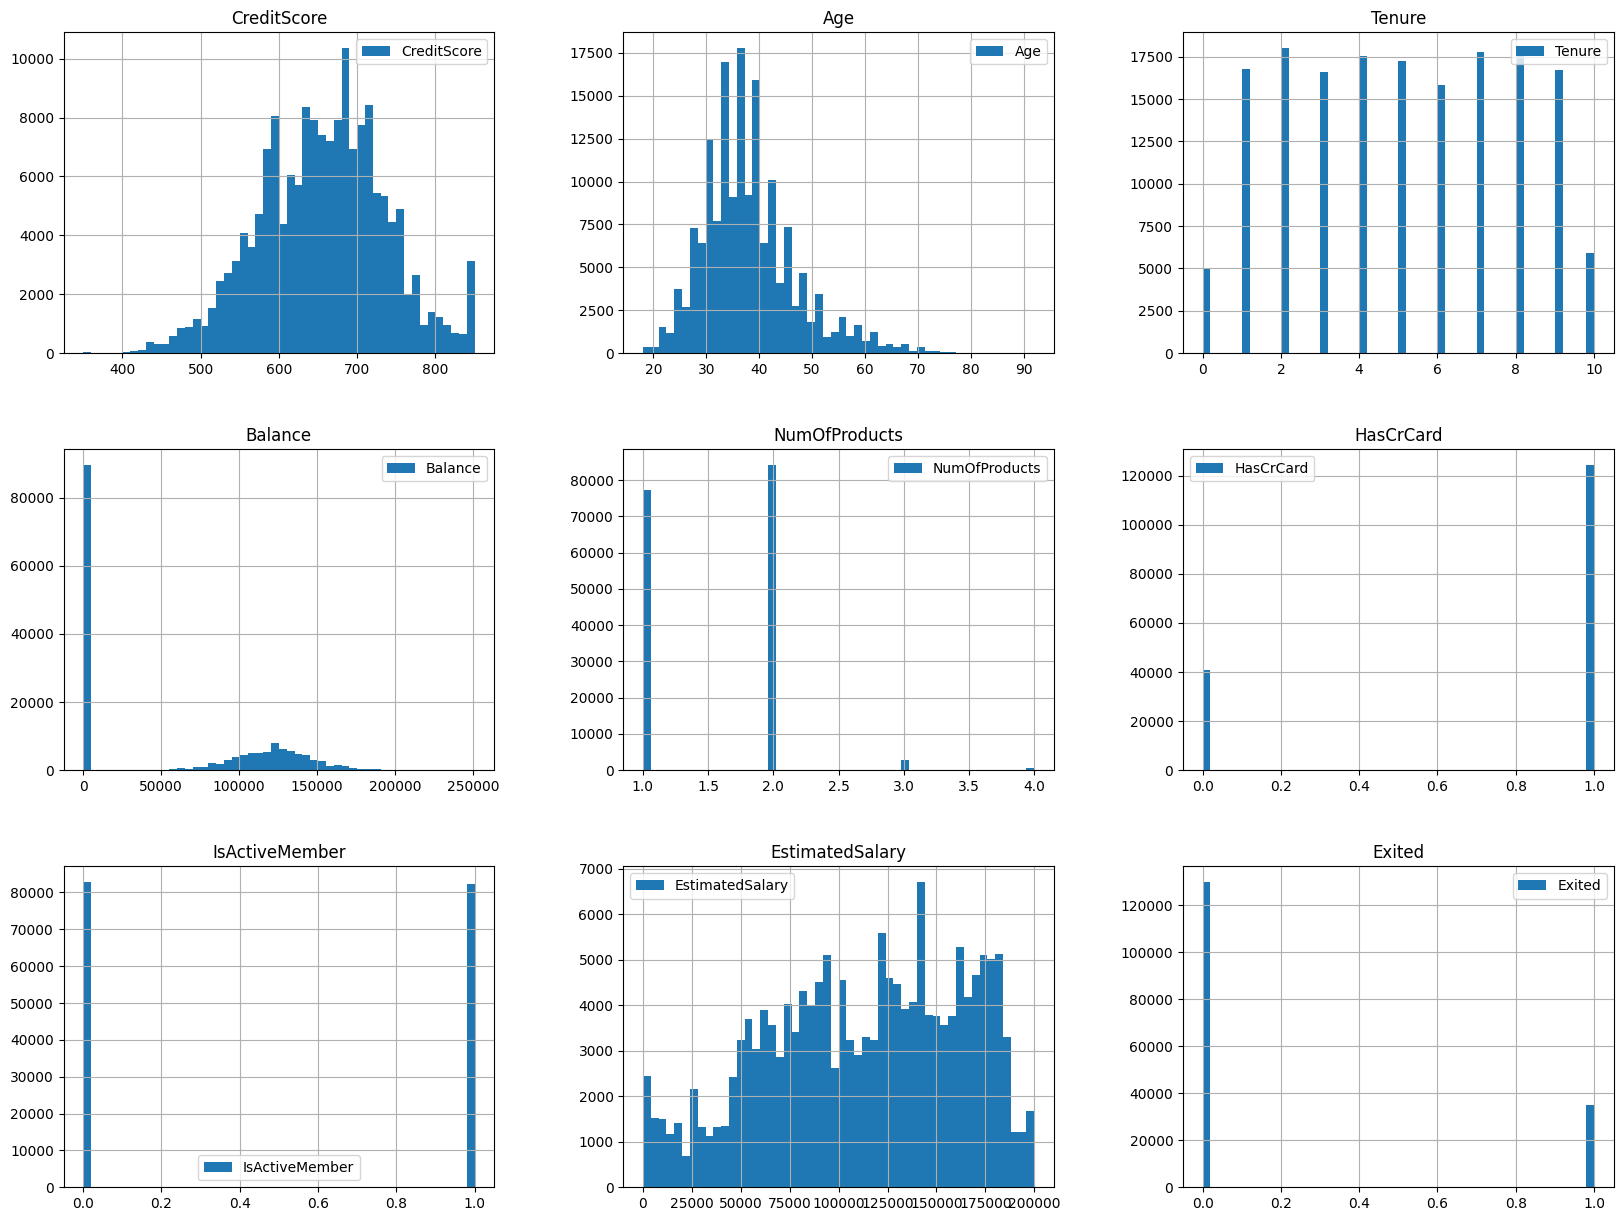

In [409]:
train[numeric_cols].hist(bins=50, figsize=(20,15), legend = True)

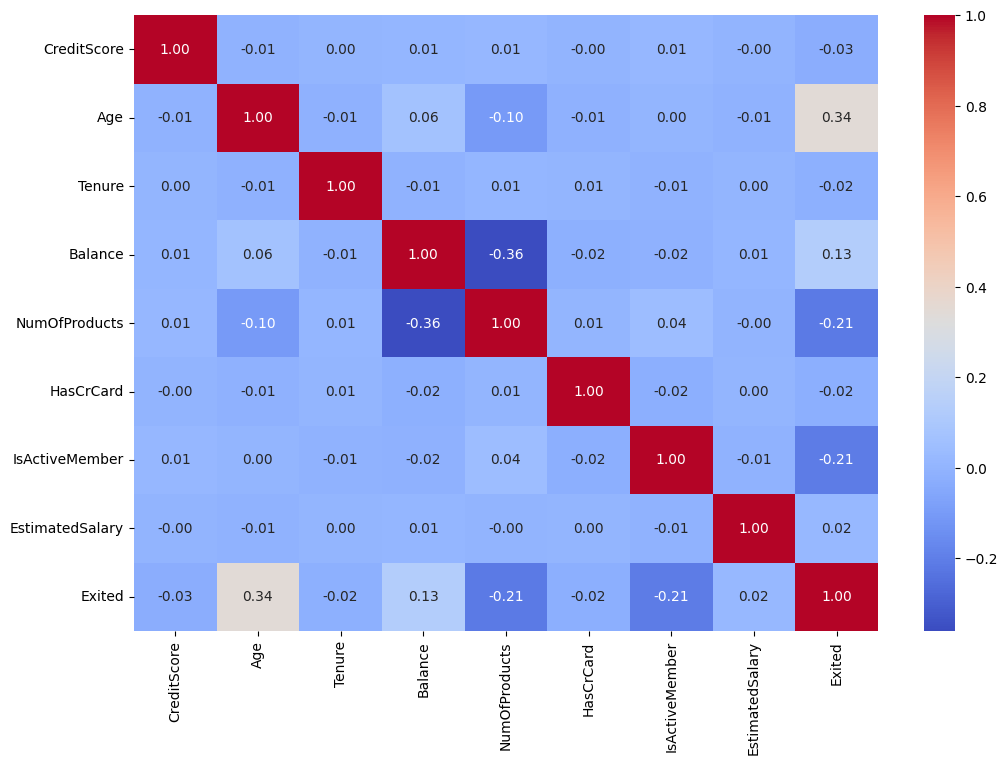

In [410]:
corr = train[numeric_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [411]:
X = train.drop(columns=['id', 'CustomerId', 'Surname', 'Exited'])
y = train['Exited']

X_test = test.drop(columns=['id', 'CustomerId', 'Surname'])

cat_cols = ['Geography', 'Gender']
num_cols = X.columns.difference(cat_cols).tolist()

In [412]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [413]:
def create_features(df):
    df = df.copy()

    df['ActiveWithCard'] = df['IsActiveMember'] * df['HasCrCard']
    df['HasBalance'] = (df['Balance'] > 0).astype(int)
    df['IsSenior'] = (df['Age'] >= 60).astype(int)
    df['TenureAgeRatio'] = df['Tenure'] / df['Age']
    df['ProductsPerTenure'] = df['NumOfProducts'] / (df['Tenure'] + 1)
    df['AgeCat'] = (df['Age'] // 20).astype('category')

    return df

In [414]:
X = create_features(X)
X_test = create_features(X_test)

for col in cat_cols:
    X[col] = X[col].astype('category')
    X_test[col] = X_test[col].astype('category')

In [415]:
# baseline model
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000)
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print('Fold AUC:', scores)
print('Mean AUC:', scores.mean())

Fold AUC: [0.81647877 0.81629268 0.81773373 0.81915234 0.81895899]
Mean AUC: 0.8177233037477658


In [416]:
params = {
    'objective': 'binary',
    'n_estimators': 1000,
    'learning_rate': 0.025,
    'num_leaves': 21,
    'max_depth': 22,
    'metric': 'auc',
    'min_data_in_leaf': 50,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'random_state': 42,
    'lambda_l2': 0.5,
    'verbosity': -1
    # 'objective': 'binary',
    # 'metric': 'auc',
    # 'n_estimators': 1000,
    # 'learning_rate': 0.025,
    # 'max_depth': 22,
    # 'num_leaves': 21,
    # 'min_data_in_leaf': 216,
    # 'min_sum_hessian_in_leaf': 3.43,
    # 'feature_fraction': 0.29,
    # 'bagging_fraction': 0.782,
    # 'bagging_freq': 4,
    # 'verbosity': -1,
    # 'random_state': 42,
    # 'n_jobs': 4
}

param_grid = {
    'lambda_l2': [0.05, 0.25, 0.5]
}

model = lgb.LGBMClassifier(**params)

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid.fit(X, y)

Fitting 5 folds for each of 3 candidates, totalling 15 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LGBMClassifier(bagging_fraction=0.8, bagging_freq=5,
                                      feature_fraction=0.9, lambda_l2=0.5,
                                      learning_rate=0.025, max_depth=22,
                                      metric='auc', min_data_in_leaf=50,
                                      n_estimators=1000, num_leaves=21,
                                      objective='binary', random_state=42,
                                      verbosity=-1),
             n_jobs=-1, param_grid={'lambda_l2': [0.05, 0.25, 0.5]},
             scoring='roc_auc', verbose=1)

In [417]:
results = pd.DataFrame(grid.cv_results_)
best_idx = grid.best_index_

for fold in range(cv.n_splits):
    score = results.loc[best_idx, f'split{fold}_test_score']
    print(f'Fold {fold + 1}: AUC = {score:.5f}')

print(f'Mean AUC: {grid.best_score_:.5f}')
print('Best Params:', grid.best_params_)

Fold 1: AUC = 0.88960
Fold 2: AUC = 0.88925
Fold 3: AUC = 0.89103
Fold 4: AUC = 0.89117
Fold 5: AUC = 0.88695
Mean AUC: 0.88960
Best Params: {'lambda_l2': 0.5}


In [418]:
lgb_model = grid.best_estimator_

print('Best params:', grid.best_params_)
print('Best CV AUC:', grid.best_score_)

Best params: {'lambda_l2': 0.5}
Best CV AUC: 0.8896008761949746


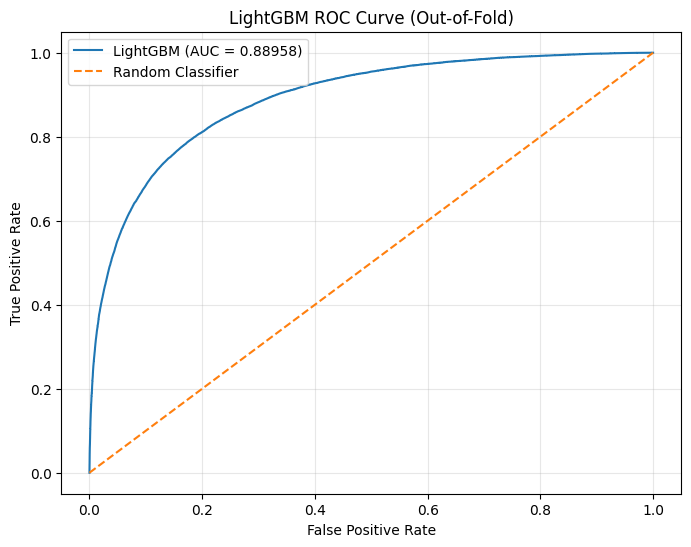

In [419]:
y_prob = cross_val_predict(
    lgb_model,
    X,
    y,
    cv=cv,
    method='predict_proba',
    n_jobs=2
)[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_prob)
auc = roc_auc_score(y, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'LightGBM (AUC = {auc:.5f})')
plt.plot([0, 1], [0, 1], '--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LightGBM ROC Curve (Out-of-Fold)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

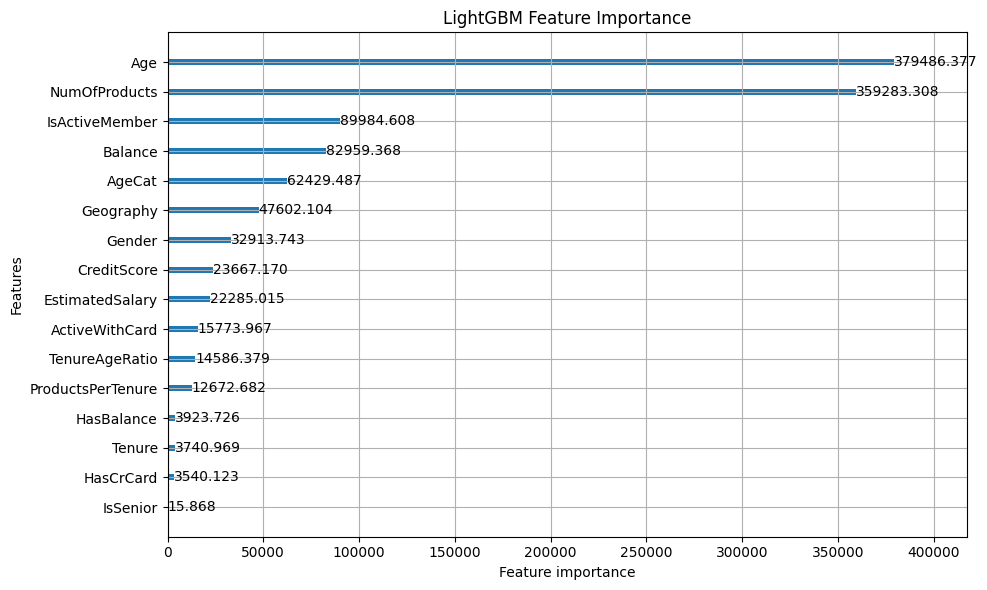

In [420]:
lgb.plot_importance(
    lgb_model,
    importance_type='gain',
    max_num_features=20,
    figsize=(10, 6)
)

plt.title('LightGBM Feature Importance')
plt.tight_layout()
plt.show()

In [421]:
pred = lgb_model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    'id': test['id'],
    'Exited': pred
})
submission.to_csv('submission.csv', index=False)